# Partie 3 – Mécanisme théorique de l'alignement et dynamique par âge et par thème (ESS11)

Ce notebook prolonge les Parties 1 et 2 à partir de la base nettoyée `output/ess11_propre.csv` (28 pays européens hors Ukraine, items normalisés sur $[0, 1]$ et structurés en 10 groupes thématiques) :

1. **Configuration et chargement** de `output/ess11_propre.csv`
2. **Simulation théorique (Baldassarri & Gelman, 2008, Fig. 1)** : comment la corrélation inter-enjeux génère une polarisation agrégée sans radicalisation individuelle
3. **Analyse empirique par âge et par groupe thématique (Kozlowski & Murphy, 2021, Fig. 1)** : estimation par B-splines cubiques sur ESS11
4. **Tests de robustesse et conclusion** : indices synthétiques `idx_<groupe>` et positionnement des partis votés `parti_lr` (ParlGov)

## 0. Imports, chemins et paramètres

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.interpolate import BSpline
from scipy import stats

DOSSIER_SORTIE = Path("output")
DOSSIER_SORTIE.mkdir(exist_ok=True)

CHEMIN_PROPRE = Path("../partie1/output/ess11_propre.csv")
if not CHEMIN_PROPRE.exists():
    CHEMIN_PROPRE = Path("partie1/output/ess11_propre.csv")

if not CHEMIN_PROPRE.exists():
    raise FileNotFoundError(f"Fichier '{CHEMIN_PROPRE}' introuvable. Exécutez d'abord la Partie 1.")

PARAMS = {
    "seed": 42,
    "bg_n_samples": 25000,
    "bg_n_dist": 800,
    "bg_rhos_density": [0.0, 0.25, 0.5, 0.75, 1.0],
    "ess_min_n": 30,
    "age_bins": [14, 24, 34, 44, 54, 64, 74, 120],
    "age_labels": ["15-24", "25-34", "35-44", "45-54", "55-64", "65-74", "75+"],
    "spline_df": 3,
    "dpi": 300,
}

# Reprise exacte des 10 groupes thématiques de la Partie 1
GROUPES_ITEMS = {
    "immigration": ["immig_meme_ethnie", "immig_autre_ethnie", "immig_pays_pauvres",
                    "immig_economie", "immig_culture", "immig_pays_meilleur"],
    "lgbt_moeurs": ["lgbt_libre", "lgbt_pas_honte", "lgbt_adoption"],
    "redistribution": ["redistrib_reduire_inegalites"],
    "ecologie": ["eco_cause_humaine", "eco_responsabilite", "eco_inquietude"],
    "europe": ["europe_integration"],
    "confiance_institutionnelle": ["confiance_parlement", "confiance_justice", "confiance_police",
                                   "confiance_politiciens", "confiance_partis", "confiance_parl_europeen", "confiance_onu"],
    "satisfaction": ["satisf_economie", "satisf_gouvernement", "satisf_democratie"],
    "religiosite": ["relig_degre", "relig_assiduite", "relig_priere"],
    "genre": ["genre_emploi_egal_famille", "genre_direction_egale", "genre_salaire_egal_eco",
              "genre_parite_parlement", "genre_conge_parental_egal", "genre_licencier_insultes",
              "genre_amende_inegalite", "genre_rejet_femmes_pouvoir", "genre_rejet_femmes_offensees",
              "genre_rejet_harcelement_exagere", "genre_percoit_ecart_salaire", "genre_rejet_protection"],
    "sante": ["sante_auto_evaluee", "sante_pas_genee", "sante_pas_deprime", "sante_pas_effort",
              "sante_sommeil_calme", "sante_heureux", "sante_pas_seul", "sante_profite_vie",
              "sante_pas_triste", "sante_motive"],
}

LABELS_GROUPES = {
    "immigration": "Immigration",
    "lgbt_moeurs": "LGBT / Mœurs",
    "redistribution": "Redistribution",
    "ecologie": "Écologie",
    "europe": "Intégration européenne",
    "confiance_institutionnelle": "Confiance institutionnelle",
    "satisfaction": "Satisfaction politique",
    "religiosite": "Religiosité",
    "genre": "Égalité de genre",
    "sante": "Santé physique & mentale",
}

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 8.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 1. Chargement de `ess11_propre.csv` et sous-échantillon analytique

In [14]:
def charger_base_partie3(chemin_csv):
    df_init = pd.read_csv(chemin_csv, low_memory=False)
    weight_col = next((w for w in ["anweight", "pspwght", "dweight"] if w in df_init.columns), None)
    if weight_col is None:
        df_init["unit_weight"] = 1.0
        weight_col = "unit_weight"

    df = df_init[df_init["age"].between(15, 105) & df_init["lrscale"].between(0, 10)].copy()
    df[weight_col] = pd.to_numeric(df[weight_col], errors="coerce").fillna(1.0)
    df["age_bin_p3"] = pd.cut(df["age"], bins=PARAMS["age_bins"], labels=PARAMS["age_labels"])

    print(f"Base Partie 1 : {len(df_init):,} répondants -> Sous-échantillon Partie 3 (âge & lrscale valides) : "
          f"{len(df):,} ({len(df)/len(df_init):.1%}) | Pondération : {weight_col}")
    display(df.groupby("age_bin_p3", observed=False)["age"].agg(Effectif="count", Age_Moyen="mean").round(1))
    return df, weight_col


df_ess, weight_col = charger_base_partie3(CHEMIN_PROPRE)

Base Partie 1 : 46,549 répondants -> Sous-échantillon Partie 3 (âge & lrscale valides) : 40,114 (86.2%) | Pondération : anweight


,Effectif,Age_Moyen
age_bin_p3,,
15-24,3416,20.1
25-34,4844,29.9
35-44,6183,39.7
45-54,6820,49.7
55-64,7229,59.6
65-74,6799,69.3
75+,4823,80.4


## 2. Modèle théorique : polarisation par corrélation sans radicalisation (Baldassarri & Gelman, 2008)

On simule $K = 4$ dimensions d'opinion suivant $\mathbf{X}_i \sim \mathcal{N}_4(\mathbf{0}, \boldsymbol{\Sigma}_\rho)$ avec corrélation paire-à-paire uniforme $\rho \in [0, 1]$ :
* **Aucune radicalisation marginale :** chaque dimension conserve une distribution $\mathcal{N}(0, 1)$ quel que soit $\rho$.
* **Dispersion agrégée :** la variance du score moyen $\bar{X}_i = \frac{1}{4}\sum_{k=1}^4 X_{ik}$ vaut $\mathrm{Var}(\bar{X}_i) = \frac{1 + 3\rho}{4}$ et quadruple lorsque $\rho$ passe de $0$ à $1$, abaissant la densité au centre modéré au profit des extrémités(Panneau A) tout en rapprochant les individus d'un même camp et en éloignant les camps opposés en distance de Manhattan (Panneau B).

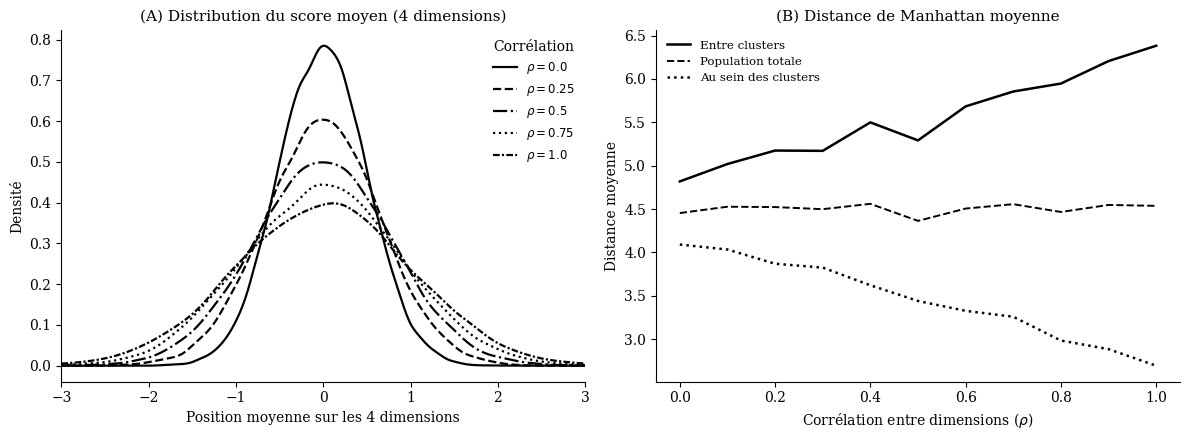

In [15]:
def generate_bg_figure1(output_pdf):
    rng = np.random.default_rng(PARAMS["seed"])
    linestyles = ["-", "--", "-.", ":", (0, (3, 1, 1, 1))]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    # Panneau A : Densité du score idéologique moyen
    grid_x = np.linspace(-3, 3, 400)
    for rho, ls in zip(PARAMS["bg_rhos_density"], linestyles):
        cov = np.full((4, 4), rho)
        np.fill_diagonal(cov, 1.0)
        mean_score = rng.multivariate_normal(np.zeros(4), cov, size=PARAMS["bg_n_samples"]).mean(axis=1)
        bw = max(1.06 * np.std(mean_score, ddof=1) * (len(mean_score) ** (-0.2)), 0.03)
        kde = np.exp(-0.5 * ((grid_x[:, None] - mean_score[None, :]) / bw) ** 2).mean(axis=1) / (bw * np.sqrt(2 * np.pi))
        axes[0].plot(grid_x, kde, linestyle=ls, color="black", linewidth=1.6, label=rf"$\rho = {rho}$")

    axes[0].set_title("(A) Distribution du score moyen (4 dimensions)")
    axes[0].set_xlabel("Position moyenne sur les 4 dimensions")
    axes[0].set_ylabel("Densité")
    axes[0].set_xlim(-3, 3)
    axes[0].legend(title="Corrélation", frameon=False)

    # Panneau B : Distance de Manhattan moyenne
    rho_grid = np.linspace(0.0, 1.0, 11)
    all_d, bet_d, wit_d = [], [], []
    for rho in rho_grid:
        cov = np.full((4, 4), rho)
        np.fill_diagonal(cov, 1.0)
        X = rng.multivariate_normal(np.zeros(4), cov, size=PARAMS["bg_n_dist"])
        clusters = (X.mean(axis=1) >= 0).astype(int)
        dmat = squareform(pdist(X, metric="cityblock"))
        iu = np.triu_indices(len(X), k=1)
        vals, same = dmat[iu], (clusters[iu[0]] == clusters[iu[1]])
        all_d.append(vals.mean())
        bet_d.append(vals[~same].mean())
        wit_d.append(vals[same].mean())

    axes[1].plot(rho_grid, bet_d, "-", color="black", lw=1.8, label="Entre clusters")
    axes[1].plot(rho_grid, all_d, "--", color="black", lw=1.4, label="Population totale")
    axes[1].plot(rho_grid, wit_d, ":", color="black", lw=1.8, label="Au sein des clusters")
    axes[1].set_title("(B) Distance de Manhattan moyenne")
    axes[1].set_xlabel(r"Corrélation entre dimensions ($\rho$)")
    axes[1].set_ylabel("Distance moyenne")
    axes[1].legend(frameon=False)

    plt.tight_layout()
    plt.savefig(output_pdf, dpi=PARAMS["dpi"], bbox_inches="tight")
    plt.show()


generate_bg_figure1(DOSSIER_SORTIE / "fig1_bg_simulation.pdf")

### Interprétation de la simulation (Baldassarri & Gelman, 2008)

Cette simulation illustre comment l'alignement entre différentes opinions peut accroître les écarts entre citoyens sans que leurs positions sur chaque sujet pris isolément ne deviennent plus extrêmes. Par construction, chacune des quatre dimensions d'opinion suit toujours la même loi normale centrée sur $0$ : les individus ne se radicalisent pas sur chaque question prise séparément.

En revanche, lorsque la corrélation $\rho$ entre les questions augmente :
* **Panneau (A) – Aplatissement de la distribution :** La distribution du score moyen $\bar{X}_i$ reste **en cloche (unimodale) et centrée sur $0$**, mais sa variance $\mathrm{Var}(\bar{X}_i) = \frac{1 + 3\rho}{4}$ est multipliée par quatre entre $\rho = 0$ et $\rho = 1$. Conformément aux conclusions de Baldassarri et Gelman (2008), la hausse de $\rho$ ne crée pas deux camps séparés, mais **aplatit et étire la distribution**, augmentant la proportion d'individus ayant des profils cohérents à gauche ou à droite.
* **Panneau (B) – Écartement entre camps :** La distance moyenne entre les individus situés à gauche ($\bar{X}_i < 0$) et ceux situés à droite ($\bar{X}_i \ge 0$) augmente nettement avec $\rho$, tandis que les individus d'un même camp deviennent plus proches les uns des autres.

## 3. Alignement idéologique par groupe thématique selon l'âge (Kozlowski & Murphy, 2021)

Pour chaque tranche d'âge décennale $a$ et chaque item $X_j$ du groupe thématique $g(j)$, on mesure l'intensité de la contrainte idéologique par la corrélation pondérée en valeur absolue $|r_{j,a}| = |\mathrm{Corr}_{w}(X_j, \mathrm{lrscale} \mid \mathrm{age} \in a)|$, puis on lisse les trajectoires de chacun des **10 groupes de la Partie 1** par B-splines cubiques ($\mathrm{df} = 3$) avec intervalles de confiance à $95\%$.

,Moyenne,Ecart_Type,Mediane,Max
label,,,,
Immigration,0.263,0.061,0.263,0.380
LGBT / Mœurs,0.206,0.046,0.197,0.282
Redistribution,0.205,0.032,0.208,0.259
Intégration européenne,0.195,0.043,0.177,0.272
Écologie,0.180,0.068,0.181,0.311
Religiosité,0.162,0.044,0.157,0.248
Égalité de genre,0.109,0.053,0.106,0.235
Satisfaction politique,0.101,0.043,0.107,0.170
Confiance institutionnelle,0.052,0.044,0.040,0.196


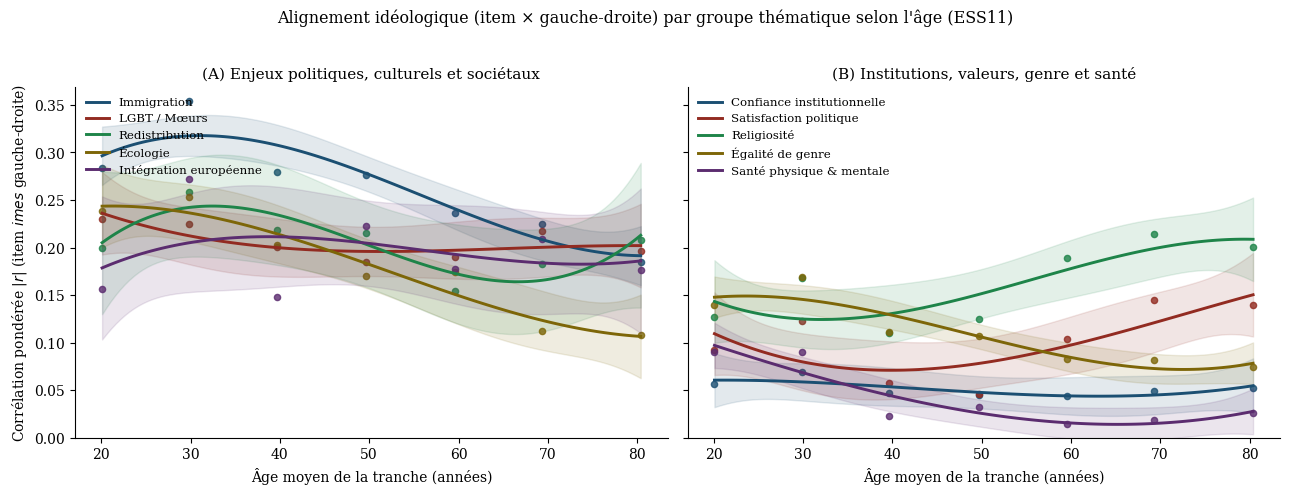

In [16]:
def weighted_corr(x, y, w):
    mask = np.isfinite(x) & np.isfinite(y) & np.isfinite(w) & (w > 0)
    if mask.sum() < PARAMS["ess_min_n"]:
        return np.nan
    x, y, w = x[mask], y[mask], w[mask]
    w_norm = w / np.sum(w)
    dx, dy = x - np.sum(w_norm * x), y - np.sum(w_norm * y)
    denom = np.sqrt(np.sum(w_norm * dx**2) * np.sum(w_norm * dy**2))
    return np.sum(w_norm * dx * dy) / denom if denom > 0 else np.nan


def fit_predict_bspline_by_group(corr_df, age_grid, df_spline=3, alpha=0.05):
    groups = sorted(corr_df["groupe"].unique())
    x_all, y_all = corr_df["age_mid"].to_numpy(), corr_df["abs_corr"].to_numpy()
    degree = 3
    n_int = max(0, df_spline - degree)
    int_knots = np.quantile(x_all, np.linspace(0, 1, n_int + 2)[1:-1]) if n_int > 0 else np.array([])
    knots = np.concatenate(([x_all.min()] * (degree + 1), int_knots, [x_all.max()] * (degree + 1)))

    B_obs = BSpline.design_matrix(x_all, knots, degree).toarray()[:, 1:]
    B_grid = BSpline.design_matrix(age_grid, knots, degree).toarray()[:, 1:]

    X_design = np.hstack([
        np.hstack([ind := (corr_df["groupe"].to_numpy() == g).astype(float)[:, None], ind * B_obs])
        for g in groups
    ])
    beta, _, _, _ = np.linalg.lstsq(X_design, y_all, rcond=None)
    resid = y_all - X_design @ beta
    dof = max(len(y_all) - np.linalg.matrix_rank(X_design), 1)
    cov_beta = (np.sum(resid**2) / dof) * np.linalg.pinv(X_design.T @ X_design)
    t_crit = stats.t.ppf(1.0 - alpha / 2.0, df=dof)

    preds = {}
    for idx_g, g in enumerate(groups):
        X_grid = np.hstack([
            np.hstack([np.ones((len(age_grid), 1)), B_grid]) if j == idx_g
            else np.zeros((len(age_grid), 1 + B_grid.shape[1]))
            for j in range(len(groups))
        ])
        mean_pred = X_grid @ beta
        se_pred = np.sqrt(np.maximum(np.sum((X_grid @ cov_beta) * X_grid, axis=1), 0.0))
        preds[g] = {"mean": mean_pred, "ci_lower": mean_pred - t_crit * se_pred, "ci_upper": mean_pred + t_crit * se_pred}
    return preds


def analyser_alignement_age_thematiques(df, groupes_dict, weight_col, target_col="lrscale", titre="", ylabel="", output_pdf=None):
    records = [
        {"age_mid": grp["age"].mean(), "groupe": g, "label": LABELS_GROUPES.get(g, g),
         "abs_corr": abs(r)}
        for _, grp in df.groupby("age_bin_p3", observed=False)
        for g, cols in groupes_dict.items()
        for col in cols if col in grp.columns
        if np.isfinite(r := weighted_corr(
            pd.to_numeric(grp[col], errors="coerce").to_numpy(),
            pd.to_numeric(grp[target_col], errors="coerce").to_numpy(),
            grp[weight_col].to_numpy()
        ))
    ]
    corr_df = pd.DataFrame(records)
    summary = (corr_df.groupby("label")["abs_corr"]
               .agg(Moyenne="mean", Ecart_Type="std", Mediane="median", Max="max")
               .sort_values("Moyenne", ascending=False))
    display(summary.round(3))

    age_grid = np.linspace(corr_df["age_mid"].min(), corr_df["age_mid"].max(), 120)
    preds = fit_predict_bspline_by_group(corr_df, age_grid, df_spline=PARAMS["spline_df"])

    panneaux = [
        (["immigration", "lgbt_moeurs", "redistribution", "ecologie", "europe"], "(A) Enjeux politiques, culturels et sociétaux"),
        (["confiance_institutionnelle", "satisfaction", "religiosite", "genre", "sante"], "(B) Institutions, valeurs, genre et santé"),
    ]
    palette = ["#1b4f72", "#922b21", "#1e8449", "#7d6608", "#5b2c6f"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

    for ax, (liste_g, sous_titre) in zip(axes, panneaux):
        for idx, g in enumerate(liste_g):
            if g not in preds:
                continue
            c, res = palette[idx % len(palette)], preds[g]
            ax.plot(age_grid, res["mean"], color=c, lw=2.1, label=LABELS_GROUPES.get(g, g))
            ax.fill_between(age_grid, res["ci_lower"], res["ci_upper"], color=c, alpha=0.12)
            pts = corr_df[corr_df["groupe"] == g].groupby("age_mid")["abs_corr"].mean().reset_index()
            ax.scatter(pts["age_mid"], pts["abs_corr"], color=c, s=20, alpha=0.8)
        ax.set_title(sous_titre)
        ax.set_xlabel("Âge moyen de la tranche (années)")
        ax.set_ylim(bottom=0)
        ax.legend(frameon=False, loc="upper left")

    axes[0].set_ylabel(ylabel)
    fig.suptitle(titre, fontsize=11.5, y=1.02)
    plt.tight_layout()
    if output_pdf:
        plt.savefig(output_pdf, dpi=PARAMS["dpi"], bbox_inches="tight")
    plt.show()
    return corr_df, summary


corr_main, summary_main = analyser_alignement_age_thematiques(
    df_ess, GROUPES_ITEMS, weight_col, target_col="lrscale",
    titre="Alignement idéologique (item × gauche-droite) par groupe thématique selon l'âge (ESS11)",
    ylabel=r"Corrélation pondérée $|r|$ (item $	imes$ gauche-droite)",
    output_pdf=DOSSIER_SORTIE / "fig2_kozlowski_ess11_age.pdf"
)

#### Interprétation de l'alignement idéologique selon l'âge (Figure 2)

Cette figure présente une **adaptation transversale** de la méthode de Kozlowski et Murphy (2021) sur les sept tranches d'âge d'ESS11 ($N = 40\,114$). Les courbes correspondent à un lissage par **polynômes de degré 3** des corrélations pondérées $|r_{j,a}|$ entre chaque question et l'auto-positionnement gauche-droite (`lrscale`), avec leurs intervalles de confiance à 95 %.

* **Hiérarchie thématique :** **L'immigration** ($|r| = \text{0,263}$) domine nettement le clivage gauche-droite, suivie d'un bloc serré réunissant les **enjeux LGBT / mœurs** ($\text{0,206}$), la **redistribution** ($\text{0,205}$) et **l'intégration européenne** ($\text{0,195}$), puis **l'écologie** ($\text{0,180}$) et la **religiosité** ($\text{0,162}$). La **santé physique et mentale** ($\text{0,042}$), retenue comme thème témoin, affiche une corrélation quasi nulle.
* **Effet de l'agrégation entre pays (cas de la confiance institutionnelle) :** Les corrélations sont ici calculées en regroupant tous les pays. Or, la **Partie 2** montre que ce choix gonfle certaines corrélations et en annule d'autres, comme la **confiance institutionnelle** ($\text{0,052}$ en agrégé), dont le signe s'inverse selon les contextes nationaux (par exemple, la confiance dans le parlement passe d'une corrélation agrégée quasi nulle à une moyenne pays par pays de $0,12$, atteignant $0,48$ en Hongrie).
* **Profils selon l'âge :** Contrairement à l'idée d'un sous-alignement généralisé des plus jeunes, l'alignement sur l'**immigration**, l'**écologie** et l'**égalité de genre** est maximal chez les jeunes adultes puis décroît avec l'âge. La baisse avec l'âge de l'alignement sur l'immigration se retrouve d'ailleurs en calculant pays par pays (de $0,23$ à $0,11$). Les enjeux **LGBT / mœurs**, la **redistribution** et l'**intégration européenne** restent globalement stables, tandis que seule la **religiosité** augmente nettement aux âges élevés.
* **Limite méthodologique :** L'enquête ESS11 étant transversale, ces profils reflètent des écarts entre cohortes présentes au moment de l'enquête, sans permettre d'isoler un effet propre au vieillissement.

## 4. Analyses de sensibilité et conclusion

Afin de vérifier que les trajectoires observées en Section 3 ne résultent pas d'artefacts de mesure propres aux questions isolées ou à l'auto-positionnement déclaré (`lrscale`), nous reconduisons l'estimation par B-splines à l'aide de deux variables construites en **Partie 1** :

1. **Indices thématiques synthétiques (`idx_<groupe>`) — validation interne (`fig3`) :**
   * *Principe :* chaque indice agrège par moyenne les items normalisés d'un même domaine (par exemple les 6 questions sur l'immigration dans `idx_immigration` ou les 12 items sur l'égalité de genre dans `idx_genre`).
   * *Intérêt méthodologique :* cette agrégation neutralise le bruit aléatoire propre aux items isolés (*biais d'atténuation* qui tire les corrélations vers zéro) et accorde un poids strictement égal à chacun des 10 thèmes, indépendamment de son nombre initial de questions.
2. **Positionnement gauche-droite du parti voté (`parti_lr`, ParlGov) — validation externe (`fig4`) :**
   * *Principe :* sur le sous-échantillon des électeurs dont le vote déclaré est rattaché à la base ParlGov ($N \ge 500$), on remplace l'auto-placement subjectif `lrscale` par le score gauche-droite attribué par des experts au parti choisi lors des dernières élections législatives.
   * *Intérêt méthodologique :* ce test limite les biais de subjectivité ou de rationalisation liés à l'auto-étiquetage politique et vérifie que l'alignement des attitudes par âge se traduit concrètement dans le **comportement électoral** effectif.

,Moyenne,Ecart_Type,Mediane,Max
label,,,,
Immigration,0.325,0.066,0.333,0.434
LGBT / Mœurs,0.248,0.018,0.239,0.269
Écologie,0.230,0.071,0.221,0.315
Égalité de genre,0.227,0.060,0.225,0.332
Redistribution,0.205,0.032,0.208,0.259
Intégration européenne,0.195,0.043,0.177,0.272
Religiosité,0.181,0.047,0.188,0.237
Satisfaction politique,0.117,0.045,0.117,0.169
Santé physique & mentale,0.061,0.058,0.030,0.146


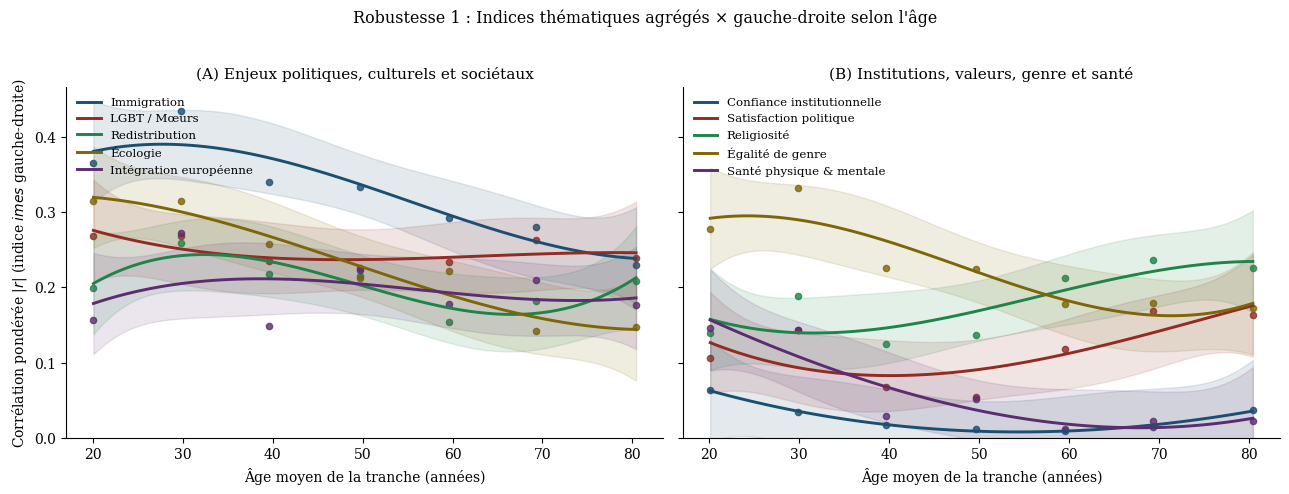

,Moyenne,Ecart_Type,Mediane,Max
label,,,,
Immigration,0.297,0.046,0.304,0.390
Intégration européenne,0.266,0.026,0.260,0.303
Écologie,0.217,0.058,0.213,0.357
Redistribution,0.205,0.038,0.212,0.272
LGBT / Mœurs,0.198,0.068,0.179,0.318
Religiosité,0.138,0.039,0.142,0.204
Confiance institutionnelle,0.125,0.062,0.107,0.274
Égalité de genre,0.097,0.052,0.094,0.210
Satisfaction politique,0.060,0.039,0.053,0.146


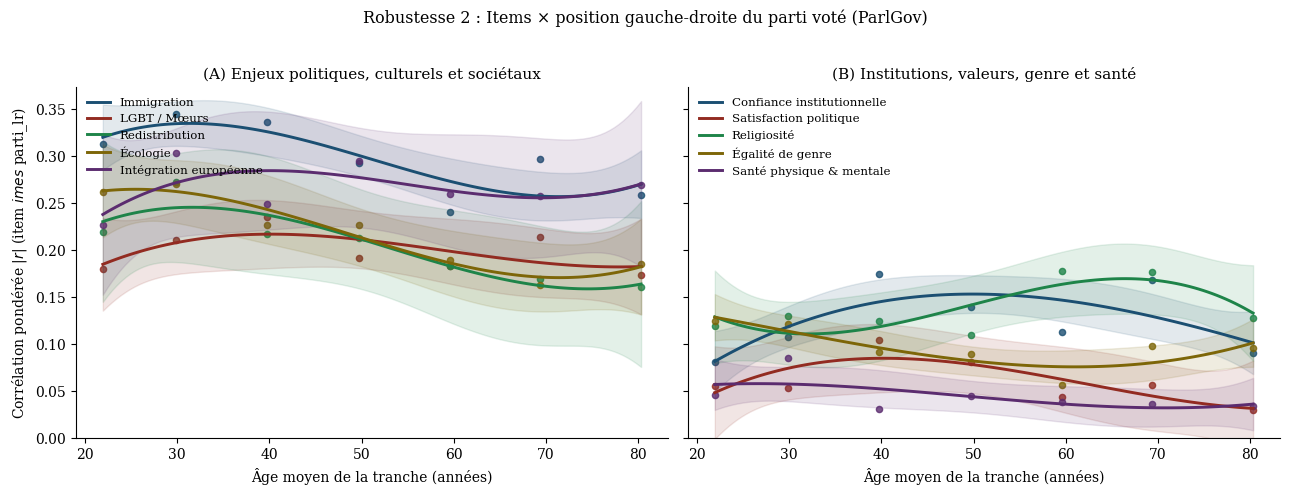

In [17]:
# Robustesse 1 : Indices thématiques agrégés (idx_<groupe>)
GROUPES_INDICES = {g: [f"idx_{g}"] for g in GROUPES_ITEMS if f"idx_{g}" in df_ess.columns}
analyser_alignement_age_thematiques(
    df_ess, GROUPES_INDICES, weight_col, target_col="lrscale",
    titre="Robustesse 1 : Indices thématiques agrégés × gauche-droite selon l'âge",
    ylabel=r"Corrélation pondérée $|r|$ (indice $	imes$ gauche-droite)",
    output_pdf=DOSSIER_SORTIE / "fig3_robustesse_indices_thematiques.pdf"
)

# Robustesse 2 : Positionnement gauche-droite du parti voté (ParlGov)
if "parti_lr" in df_ess.columns and df_ess["parti_lr"].notna().sum() >= 500:
    analyser_alignement_age_thematiques(
        df_ess[df_ess["parti_lr"].notna()], GROUPES_ITEMS, weight_col, target_col="parti_lr",
        titre="Robustesse 2 : Items × position gauche-droite du parti voté (ParlGov)",
        ylabel=r"Corrélation pondérée $|r|$ (item $	imes$ parti_lr)",
        output_pdf=DOSSIER_SORTIE / "fig4_robustesse_parti_parlgov.pdf"
    )

#### Robustesse 1 : Indices thématiques agrégés

L'agrégation des items en indices standardisés par thème confirme les résultats principaux tout en corrigeant le biais d'atténuation lié au bruit de mesure des questions isolées :

* **Renforcement de l'alignement sur les thèmes multi-items :** La réduction de la variance d'échantillonnage relève sensiblement les corrélations sur les dimensions composées de plusieurs indicateurs (en particulier l'**immigration**, l'**égalité de genre** et l'**écologie**), tandis que les thèmes à item unique (**redistribution**, **intégration européenne**) restent inchangés et que le thème témoin (**santé**) demeure proche de zéro.
* **Stabilité des profils selon l'âge :** L'ensemble des trajectoires générationnelles observées sur les items bruts est préservé (décroissance avec l'âge pour l'immigration, l'écologie et le genre ; stabilité pour les enjeux sociétaux et européens ; hausse pour la religiosité).

#### Robustesse 2 : Position gauche-droite du parti voté (ParlGov)

En remplaçant l'auto-placement subjectif (`lrscale`) par le score gauche-droite attribué par des experts au parti voté (`parti_lr`, sur les $N = \text{18 899}$ électeurs appariés), ce test limite les biais liés à l'auto-étiquetage idéologique :

* **Confirmation dans les urnes :** La hiérarchie des enjeux structurants du Panneau (A) est retrouvée, avec l'**immigration** en tête devant l'**intégration européenne**, dont le poids s'avère encore plus marqué dans le choix partisan que dans l'auto-identification gauche-droite.
* **Nuances selon l'âge et rapport aux institutions :** Chez les jeunes électeurs, l'alignement entre opinions et vote partisan se cristallise progressivement entre 22 et 35 ans, tandis que l'alignement sur l'immigration reste élevé chez les électeurs âgés. Dans le Panneau (B), la **confiance institutionnelle** apparaît davantage liée au parti voté qu'à l'auto-placement, traduisant la captation de la défiance politique par des partis situés aux extrêmes de l'échelle ParlGov.

### Conclusion

La simulation de Baldassarri et Gelman (2008) montre qu'un simple alignement corrélé entre opinions suffit à produire une polarisation agrégée (écartement entre camps et homogénéisation interne) sans radicalisation marginale sur chaque sujet pris isolément.

Appliquée aux données transversales d'ESS11 sur 28 pays européens ($N = \text{40 114}$), l'estimation par polynômes de degré 3 met en évidence trois enseignements :
* **Une structuration multidimensionnelle de l'axe gauche-droite :** Le clivage idéologique en Europe est dominé par l'immigration, suivie des enjeux culturels (LGBT / mœurs), de la redistribution économique, de l'intégration européenne et de l'écologie, tandis que le thème témoin (santé) reste non aligné et que la confiance institutionnelle masque des oppositions de signes entre pays.
* **Des profils contrastés selon l'âge :** Loin d'un alignement uniformément croissant avec l'âge, les jeunes cohortes présentent une structuration plus marquée sur l'immigration, l'écologie et l'égalité de genre, alors que les enjeux sociétaux, économiques et européens restent relativement stables et que seule la religiosité s'aligne davantage aux âges élevés.
* **Une robustesse confirmée :** L'agrégation en indices thématiques confirme ces dynamiques en réduisant le biais d'atténuation, et le croisement avec le score ParlGov des partis votés  atteste que cet alignement — en particulier sur l'immigration et l'intégration européenne — se traduit dans le comportement électoral.

In [18]:
col_poids = "anweight" if "anweight" in df_ess.columns else "pspwght"
cols_age = [c for c in df_ess.columns if "age" in c.lower() or "tranche" in c.lower()]
col_age = cols_age[0] if cols_age else None

cols_lr = ["lrscale", col_poids] + ([col_age] if col_age else [])
cols_pg = ["parti_lr", col_poids] + ([col_age] if col_age else [])

print("Nombre de pays :", df_ess["cntry"].nunique())
print("N total base   :", len(df_ess))
print("N lrscale      :", df_ess[cols_lr].dropna().shape[0])
print("N ParlGov      :", df_ess[cols_pg].dropna().shape[0])

Nombre de pays : 28
N total base   : 40114
N lrscale      : 40114
N ParlGov      : 18899
